# KNN: k-Nearest Neighbors

**Aprendizaje Automático — presentación virtual**

KNN es un algoritmo **supervised**, **non-parametric** y de **lazy learning**:
no construye un modelo, guarda el conjunto de **train** y decide al predecir
comparando con los ejemplos más parecidos.

**Recorrido**

1. ¿Qué es KNN?
2. Datos de ejemplo
3. Distancia euclidiana
4. Ejemplo numérico
5. Implementación y escalado
6. Por qué estandarizar
7. Elección de `k`
8. Frontera de decisión
9. Evaluación
10. Variantes
11. Complejidad y límites
12. Conclusiones

> Todas las celdas ya están ejecutadas: las salidas y los gráficos están
> guardados para compartir pantalla.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({
    "figure.dpi": 120,
    "font.size": 13,
    "axes.titlesize": 14,
    "axes.labelsize": 13,
    "legend.fontsize": 11,
})


## 1. ¿Qué es KNN?

- **Supervised**: aprende de pares `(X, y)` con etiquetas.
- **Non-parametric**: no impone una forma concreta a la frontera.
- **Lazy learning**: no hay fase de entrenamiento; se guarda el dataset y se
  trabaja al predecir.
- **Classification**: los `k` vecinos votan la clase mayoritaria.
- **Regression**: los `k` vecinos promedian su valor.

Por eso KNN no tiene pesos que ajustar: su «modelo» es el propio **train set**.


## 2. Datos de ejemplo

Dos nubes gaussianas 2D con solapamiento: **no son separables al 100 %**.

- 120 puntos por clase, 240 en total.
- 70 % para **train**, 30 % para **test**.
- Etiquetas `0` y `1`.


Forma de X: (240, 2)
Puntos por clase: [120 120]


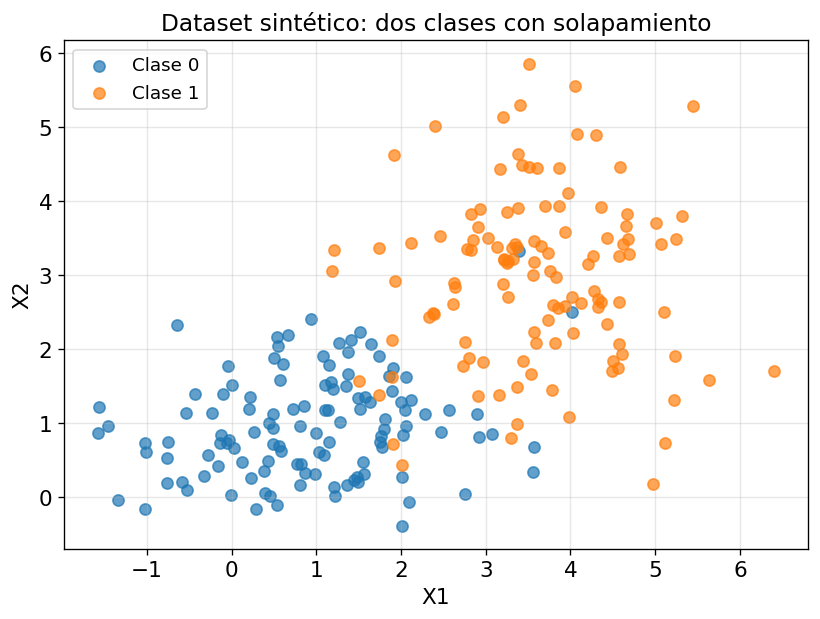

In [2]:
rng = np.random.default_rng(42)

X_clase0 = rng.normal(loc=[1.0, 1.0], scale=[1.2, 0.8], size=(120, 2))
X_clase1 = rng.normal(loc=[3.5, 3.0], scale=[1.0, 1.1], size=(120, 2))

X = np.vstack([X_clase0, X_clase1])
y = np.repeat([0, 1], 120)

print("Forma de X:", X.shape)
print("Puntos por clase:", np.bincount(y))

plt.figure(figsize=(8, 5.5))
plt.scatter(X[y == 0, 0], X[y == 0, 1], s=45, alpha=0.7, label="Clase 0")
plt.scatter(X[y == 1, 0], X[y == 1, 1], s=45, alpha=0.7, label="Clase 1")
plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Dataset sintético: dos clases con solapamiento")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


**Lectura del código**

- `default_rng(42)` fija la semilla: el dataset es reproducible.
- `rng.normal(loc, scale, size)` genera cada nube gaussiana; `loc` es el centro
  y `scale` la desviación en cada eje.
- `np.vstack` apila las dos nubes y `np.repeat` crea las etiquetas.
- `np.bincount(y)` cuenta cuántos puntos hay de cada clase.
- El gráfico usa una **máscara booleana** (`X[y == 0, 0]`): selecciona solo las
  filas de una clase.


## 3. Distancia euclidiana

La cercanía se mide con la distancia euclidiana:

$$d(a,b)=\sqrt{\sum_i (a_i-b_i)^2}$$

También existen **Manhattan** (`Σ|aᵢ-bᵢ|`), útil con ruido o datos en rejilla,
**Minkowski** (generaliza ambas) y **cosine**, habitual en texto.


In [3]:
def distancia_euclidiana(a, b):
    # Raiz de la suma de diferencias al cuadrado
    return np.sqrt(np.sum((a - b) ** 2))


def distancias_a_todos(x, X):
    # Distancia de x a cada fila de X (vectorizado, sin bucles)
    return np.sqrt(np.sum((X - x) ** 2, axis=1))


print("d((1,1), (4,5)) =", distancia_euclidiana(np.array([1, 1]), np.array([4, 5])))
print("distancias del origen a [(3,4), (0,0), (1,1)]:",
      distancias_a_todos(np.zeros(2), np.array([[3, 4], [0, 0], [1, 1]])))


d((1,1), (4,5)) = 5.0
distancias del origen a [(3,4), (0,0), (1,1)]: [5.    0.    1.414]


**Lectura del código**

- `a - b` resta vectorialmente; `** 2` eleva al cuadrado; `np.sum` suma; `sqrt`
  da la distancia.
- En `distancias_a_todos`, `X - x` funciona por **broadcasting**: `x` se resta a
  todas las filas de `X`.
- `axis=1` suma cada fila, así se obtiene una distancia por punto.
- Salida esperada: `5.0` y `[5.0, 0.0, 1.414]`.


## 4. Ejemplo numérico

Consulta $q=(2,3)$ y cinco puntos de **train**:

| Punto | Coordenadas | Clase | Distancia a `q` |
|---|---|---|---|
| A | (1, 1) | 0 | 2.236 |
| B | (2, 2) | 0 | **1.000** |
| C | (4, 5) | 1 | 2.828 |
| D | (5, 5) | 1 | 3.606 |
| E | (1, 4) | 1 | **1.414** |

Con $k=3$, los vecinos son **B, E y A**: dos de clase 0 y uno de clase 1.
Predicción: **clase 0**.


In [4]:
def predecir_uno(x, X_train, y_train, k=3):
    d = distancias_a_todos(x, X_train)
    indices = np.argsort(d, kind="stable")[:k]   # k vecinos mas cercanos
    etiquetas = y_train[indices]
    clases, conteos = np.unique(etiquetas, return_counts=True)
    return clases[np.argmax(conteos)], d[indices], etiquetas


X_toy = np.array([[1, 1], [2, 2], [4, 5], [5, 5], [1, 4]])
y_toy = np.array([0, 0, 1, 1, 1])
q = np.array([2, 3])

prediccion, dist, etiquetas = predecir_uno(q, X_toy, y_toy, k=3)

print("Distancias de los 3 vecinos:", np.round(dist, 3))
print("Clases de los 3 vecinos:      ", etiquetas)
print("Prediccion final:", prediccion)


Distancias de los 3 vecinos: [1.    1.414 2.236]
Clases de los 3 vecinos:       [0 1 0]
Prediccion final: 0


**Lectura del código**

- `np.argsort(d, kind="stable")` devuelve los índices ordenados por distancia;
  `[:k]` toma los `k` más cercanos. `stable` hace reproducibles los empates.
- `y_train[indices]` recupera las etiquetas de esos vecinos.
- `np.unique(..., return_counts=True)` cuenta votos; `argmax` elige la clase
  ganadora.
- La función devuelve también las distancias y las etiquetas para poder
  inspeccionar la decisión.


## 5. Implementación y escalado

Usamos la clase `KNN` de `knn.py`. El flujo es el estándar de **supervised
learning**:

1. **train/test split**;
2. **standardization** ajustada solo con `train`;
3. `fit`, `predict` y evaluación con `score`.

Estandarizar es obligatorio en KNN: la distancia suma todas las variables y una
escala grande dominaría el resultado.


In [5]:
from knn import KNN, Estandarizador, dividir_train_test, matriz_confusion

X_train, X_test, y_train, y_test = dividir_train_test(X, y, test_size=0.3, random_state=7)

est = Estandarizador().fit(X_train)          # media y desviacion SOLO del train
X_train_esc = est.transform(X_train)
X_test_esc = est.transform(X_test)

modelo = KNN(k=5).fit(X_train_esc, y_train)

print("Train:", X_train_esc.shape, "| Test:", X_test_esc.shape)
print("Accuracy en test:", round(modelo.score(X_test_esc, y_test), 3))
print("Predicciones:", modelo.predict(X_test_esc[:8]))
print("Probabilidades de las 5 primeras filas:")
print(np.round(modelo.predict_proba(X_test_esc[:5]), 3))


Train: (168, 2) | Test: (72, 2)
Accuracy en test: 0.944
Predicciones: [1 1 1 0 0 0 0 0]
Probabilidades de las 5 primeras filas:
[[0. 1.]
 [0. 1.]
 [0. 1.]
 [1. 0.]
 [1. 0.]]


**Lectura del código y de la salida**

- `dividir_train_test` devuelve cuatro arrays: `X_train, X_test, y_train, y_test`;
  con `random_state=7` el split es reproducible. Quedan **168** de train y **72**
  de test.
- `Estandarizador().fit(X_train)` calcula media y desviación de cada columna.
  `transform` aplica `(x - media) / desviación`; se usa el mismo objeto en test.
- `KNN(k=5).fit(...)` no calcula nada: solo guarda `X_train` e `y_train` y
  valida los datos.
- `score` compara predicciones con etiquetas reales y devuelve la fracción de
  aciertos (**0.944**).
- `predict_proba` devuelve una matriz `(n_puntos, n_clases)`; cada fila suma 1.
  Aquí las primeras filas son `[0, 1]`: los 5 vecinos votaron todos clase 1.


## 6. Por qué estandarizar

Añadimos una tercera variable **irrelevante** con escala grande (media 1000).
Sin escalar, domina la distancia y el modelo se degrada.


In [6]:
rng_ruido = np.random.default_rng(1)
ruido = rng_ruido.normal(loc=1000, scale=300, size=(X.shape[0], 1))
X_ruido = np.hstack([X, ruido])   # tercera columna irrelevante a gran escala

Xr_train, Xr_test, yr_train, yr_test = dividir_train_test(X_ruido, y, test_size=0.3, random_state=7)

sin_escalar = KNN(k=5).fit(Xr_train, yr_train)
print("Sin estandarizar:", round(sin_escalar.score(Xr_test, yr_test), 3))

est_ruido = Estandarizador().fit(Xr_train)
con_escalado = KNN(k=5).fit(est_ruido.transform(Xr_train), yr_train)
print("Estandarizado:   ", round(con_escalado.score(est_ruido.transform(Xr_test), yr_test), 3))


Sin estandarizar: 0.486
Estandarizado:    0.944


**Lectura del código y de la salida**

- Se genera una columna de ruido con media 1000 y desviación 300, y se añade con
  `np.hstack`.
- Se repite el split con la misma semilla para comparar en igualdad de
  condiciones.
- **Sin estandarizar** la accuracy cae a **0.486**: la columna de ruido domina la
  distancia euclidiana.
- **Estandarizado** vuelve a **0.944**: las tres columnas pesan de forma
  comparable.
- Regla: ajustar el escalado solo con `train`; usar todo el dataset produce
  **data leakage**.


## 7. Elección de `k`

`k` es el **hyperparameter** principal y controla el **bias-variance tradeoff**:

- `k` pequeño → frontera irregular, **overfitting**.
- `k` grande → frontera suave, **underfitting**.

En la práctica se elige con **cross-validation** sobre el train; el test se
reserva para la evaluación final. Aquí usamos el test solo para mostrar la
tendencia.


Accuracy por k: [0.903, 0.931, 0.944, 0.944, 0.931, 0.944, 0.944, 0.944, 0.958, 0.944]
Mejor k: 31 -> 0.958


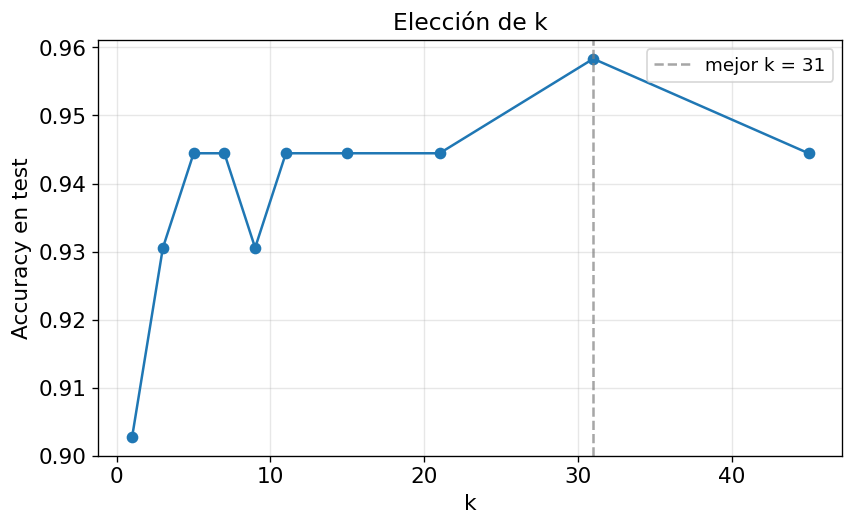

In [7]:
valores_k = [1, 3, 5, 7, 9, 11, 15, 21, 31, 45]
accuracies = []

for k in valores_k:
    m = KNN(k=k).fit(X_train_esc, y_train)
    accuracies.append(m.score(X_test_esc, y_test))

mejor_k = valores_k[int(np.argmax(accuracies))]
print("Accuracy por k:", [round(a, 3) for a in accuracies])
print("Mejor k:", mejor_k, "->", round(max(accuracies), 3))

plt.figure(figsize=(8, 4.5))
plt.plot(valores_k, accuracies, marker="o")
plt.axvline(mejor_k, color="gray", linestyle="--", alpha=0.7, label=f"mejor k = {mejor_k}")
plt.xlabel("k")
plt.ylabel("Accuracy en test")
plt.title("Elección de k")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


**Lectura del código y de la salida**

- El bucle crea un `KNN` para cada `k`, lo ajusta al train y mide accuracy en
  test.
- `np.argmax(accuracies)` devuelve la posición del máximo; se usa para recuperar
  `mejor_k = 31` y su accuracy **0.958**.
- La curva es casi plana porque el dataset es fácil y hay solo 72 puntos de
  test. Con ruido o más dimensiones, la diferencia entre valores de `k` crece.
- En un trabajo real, este barrido se hace con **cross-validation** sobre el
  train, no sobre el test.


## 8. Frontera de decisión

Cada zona de color es la clase que predice KNN en esa región.

- `k = 1`: diagrama de **Voronoi**, la frontera se pega a cada punto →
  **overfitting**.
- `k` elegido: frontera más suave y estable.


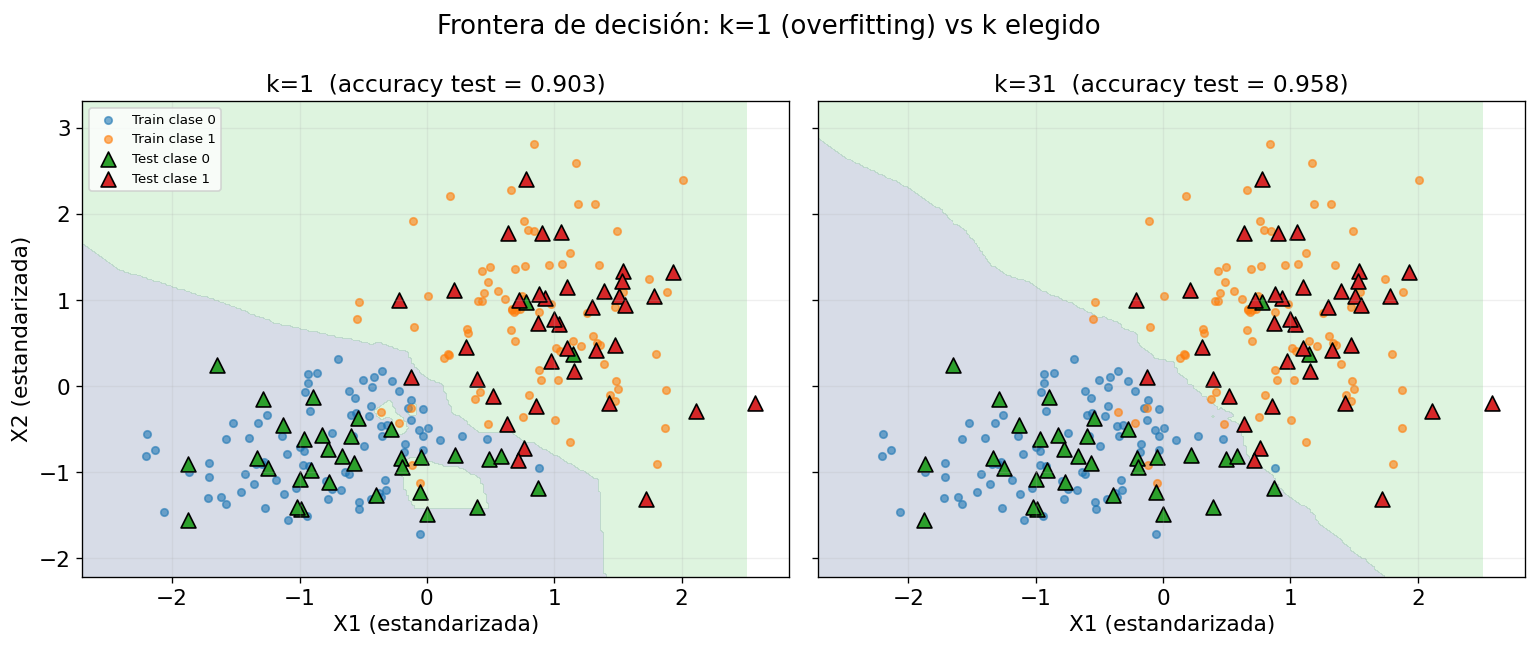

In [8]:
def graficar_frontera(ax, modelo, mostrar_leyenda=False):
    margen = 0.5
    x_min, x_max = X_train_esc[:, 0].min() - margen, X_train_esc[:, 0].max() + margen
    y_min, y_max = X_train_esc[:, 1].min() - margen, X_train_esc[:, 1].max() + margen
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 250), np.linspace(y_min, y_max, 250))
    Z = modelo.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.2, levels=[-0.5, 0.5, 1.5])
    ax.scatter(X_train_esc[y_train == 0, 0], X_train_esc[y_train == 0, 1], s=20, alpha=0.6, label="Train clase 0")
    ax.scatter(X_train_esc[y_train == 1, 0], X_train_esc[y_train == 1, 1], s=20, alpha=0.6, label="Train clase 1")
    ax.scatter(X_test_esc[y_test == 0, 0], X_test_esc[y_test == 0, 1], s=80, marker="^", edgecolors="black", label="Test clase 0")
    ax.scatter(X_test_esc[y_test == 1, 0], X_test_esc[y_test == 1, 1], s=80, marker="^", edgecolors="black", label="Test clase 1")
    ax.set_title(f"k={modelo.k}  (accuracy test = {modelo.score(X_test_esc, y_test):.3f})")
    ax.set_xlabel("X1 (estandarizada)")
    ax.grid(alpha=0.2)
    if mostrar_leyenda:
        ax.legend(fontsize=8)


modelo_final = KNN(k=mejor_k).fit(X_train_esc, y_train)
modelo_k1 = KNN(k=1).fit(X_train_esc, y_train)

fig, ejes = plt.subplots(1, 2, figsize=(13, 5.5), sharex=True, sharey=True)
graficar_frontera(ejes[0], modelo_k1, mostrar_leyenda=True)
graficar_frontera(ejes[1], modelo_final)
ejes[0].set_ylabel("X2 (estandarizada)")
fig.suptitle("Frontera de decisión: k=1 (overfitting) vs k elegido")
fig.tight_layout()
plt.show()


**Lectura del código**

- `np.meshgrid` construye una rejilla de 250 × 250 puntos que cubre el plano.
- `.ravel()` aplana la rejilla y `np.c_` la convierte en pares `(x1, x2)`; luego
  se predice **toda la rejilla** de una vez.
- `.reshape(xx.shape)` devuelve la forma 2D para dibujar con `contourf`; los
  niveles `[-0.5, 0.5, 1.5]` separan las dos clases.
- Los puntos de train se dibujan con círculos y los de test con triángulos.
- Se repite el dibujo para `k=1` y para el `k` elegido: el contraste muestra
  **overfitting** frente a una frontera estable.


## 9. Evaluación

- **Accuracy**: fracción de aciertos.
- **Precision**: de lo predicho como clase $c$, cuánto era $c$.
- **Recall**: de lo que era clase $c$, cuánto se detectó.
- **Confusion matrix**: filas = clase real, columnas = clase predicha.


In [9]:
y_pred = modelo_final.predict(X_test_esc)

matriz, clases = matriz_confusion(y_test, y_pred)
print("Clases:", clases)
print("Matriz de confusión (filas = real, columnas = predicho):")
print(matriz)
print("Accuracy:", round(float(np.mean(y_pred == y_test)), 3))

for c in clases:
    tp = np.sum((y_pred == c) & (y_test == c))
    fp = np.sum((y_pred == c) & (y_test != c))
    fn = np.sum((y_pred != c) & (y_test == c))
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    print(f"Clase {c}: precision={precision:.3f}  recall={recall:.3f}")

distancias, indices = modelo_final.kneighbors(X_test_esc[:1], n_neighbors=5)
print("Vecinos del primer punto de test (5 más cercanos):")
for d, i in zip(distancias[0], indices[0]):
    print(f"  d={d:.3f}  clase={y_train[i]}")


Clases: [0 1]
Matriz de confusión (filas = real, columnas = predicho):
[[32  2]
 [ 1 37]]
Accuracy: 0.958
Clase 0: precision=0.970  recall=0.941
Clase 1: precision=0.949  recall=0.974
Vecinos del primer punto de test (5 más cercanos):
  d=0.128  clase=1
  d=0.210  clase=1
  d=0.220  clase=1
  d=0.223  clase=1
  d=0.224  clase=1


**Lectura del código y de la salida**

- `matriz_confusion` recorre las clases y cuenta pares `(real, predicho)`; la
  matriz queda `[[32, 2], [1, 37]]`.
- `tp`, `fp` y `fn` se calculan con máscaras booleanas: verdaderos positivos,
  falsos positivos y falsos negativos de cada clase.
- `precision = tp / (tp + fp)` y `recall = tp / (tp + fn)`.
- **Accuracy 0.958**; precisión y recall cercanos a 0.95 en ambas clases.
- `kneighbors(..., n_neighbors=5)` devuelve distancias e índices; al indexar
  `y_train` se ven las clases de los 5 vecinos. Todos son clase 1, coherente con
  la predicción.


## 10. Variantes: pesos y métricas

- `pesos="uniforme"`: un voto por vecino.
- `pesos="distancia"`: cada vecino pesa $1/(d+\varepsilon)$.
- `metrica="euclidiana"` o `"manhattan"`.

No hay una combinación universalmente mejor: depende del dataset.


In [10]:
print(f"{'pesos':<12}{'métrica':<14}{'accuracy':>10}")
for pesos in ("uniforme", "distancia"):
    for metrica in ("euclidiana", "manhattan"):
        m = KNN(k=mejor_k, metrica=metrica, pesos=pesos).fit(X_train_esc, y_train)
        print(f"{pesos:<12}{metrica:<14}{m.score(X_test_esc, y_test):>10.3f}")


pesos       métrica         accuracy
uniforme    euclidiana         0.958
uniforme    manhattan          0.931
distancia   euclidiana         0.944
distancia   manhattan          0.944


**Lectura del código y de la salida**

- Dos bucles anidados recorren las 4 combinaciones de `pesos` y `metrica`; cada
  combinación se entrena y evalúa.
- `{valor:<12}` alinea a la izquierda y `{valor:>10.3f}` a la derecha con 3
  decimales: es solo formato de tabla.
- Resultados: uniforme + euclidiana **0.958**, uniforme + Manhattan **0.931**,
  distancia + euclidiana **0.944**, distancia + Manhattan **0.944**.
- Ninguna variante gana siempre; se elige con validación.


## 11. Complejidad y límites

| Fase | Coste |
|---|---|
| Entrenamiento | `O(1)`; memoria `O(n·d)` |
| Predicción de un punto | `O(n·d)` |
| Predicción de `m` puntos | `O(m·n·d)` |

- **KD-tree / Ball tree** aceleran la búsqueda en baja dimensión.
- **Curse of dimensionality**: en alta dimensión las distancias se igualan y
  «vecino más cercano» pierde sentido.
- Para **regression**, KNN promedia el valor de los vecinos en lugar de votar.


## 12. Conclusiones

1. KNN **memoriza**, no entrena: el coste está en predecir.
2. La calidad depende de la **distancia**, la **escala** y **k**.
3. Es simple e intuitivo, pero **caro** y sensible a la **dimensionalidad**.

**¿Preguntas?**


## Apéndice: `knn.py` por dentro

| Función / clase | Entradas | Salidas | Idea clave |
|---|---|---|---|
| `distancias(X, X_train)` | `(m, d)` y `(n, d)` | matriz `(m, n)` | Broadcasting; euclidiana o Manhattan |
| `KNN.fit(X, y)` | train | `self` | Solo guarda y valida; no entrena |
| `KNN.kneighbors(X)` | puntos | `(distancias, índices)` `(m, k)` | `argsort` estable y `take_along_axis` |
| `KNN._votos(...)` | distancias e índices | matriz `(m, n_clases)` | Votos uniformes o `1/(d+ε)` |
| `KNN.predict(X)` | puntos | etiquetas | `argmax` de los votos; empate → etiqueta menor |
| `KNN.predict_proba(X)` | puntos | `(m, n_clases)` | Normaliza los votos por fila |
| `KNN.score(X, y)` | test | float | Fracción de aciertos |
| `Estandarizador` | train | train/test escalados | `(x - media) / desviación`, ajustado solo con train |
| `dividir_train_test` | `X, y` | 4 arrays | Permutación con semilla y corte |
| `matriz_confusion` | `y_true, y_pred` | matriz + clases | Filas reales, columnas predichas |
| `_graficar_frontera` | modelo + datos | PNG | Rejilla, `predict`, `contourf` |

### Flujo de una predicción

```
modelo = KNN(k=5).fit(X_train, y_train)
modelo.predict(X_test)
  -> kneighbors(X_test)
     -> distancias(X_test, X_train)        # matriz (m, n)
     -> argsort(...)[:, :5]                # índices de vecinos
  -> _votos(distancias, índices)           # matriz (m, n_clases)
  -> argmax(...)                           # etiqueta por punto
```

La explicación completa, con el código línea por línea y las fórmulas, está en
`EXPLICACION.md`.
